# 40 — Question 1: growth, protection and fidelity

How fast has eVTOL patenting grown, how much of it is still protected, and do the patented aircraft stand for the aircraft the sector builds?

Sub-questions 1.1, 1.2, 1.3 of the Labelling Analysis (2026-09-30). Every path comes from `labelling_analysis.yaml`; equations come from `lib/`, figures and tables from `viz/`.

This notebook reproduces every figure, table and number of chapter 1 of the 45-page document, and compares them with it (`viz.checks`). The one difference expected is the class fold of 2026-10-01 (Stopped/Slowed Rotor Wing folds into Lift + Cruise, no longer into Electric Rotorcraft); it only touches the five-class views and is labelled where it shows.

Outputs are written to `<output>/q1_growth_protection_fidelity/` (figures: pdf, png, csv, json; tables: csv, json). Regenerate this notebook with `python3 notebooks/_build/build_40.py`.

## 0. Setup: paths and the analysis unit

The table lists every input this notebook can read, whether it exists and when it last changed. The load raises if a required input is missing.

In [1]:
import sys, pathlib
PILLAR = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(PILLAR))
import pandas as pd
pd.set_option('display.max_colwidth', 120)
from viz import config, data
cfg = config.load()
config.show(cfg)[['group', 'key', 'exists', 'modified', 'size', 'path']]

,group,key,exists,modified,size,path
0,root,labelled,True,2026-09-25 14:05,dir,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED
1,root,evtolnews,True,2026-09-22 15:12,dir,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/EVTOLNEWS_DS
2,root,reference,True,2026-09-30 18:42,dir,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analys...
3,root,output,True,2026-10-01 19:52,dir,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analys...
4,labelled_dataset,aircraft_labels,True,2026-10-01 16:38,"2,211 KB",/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/0_labelling/output...
5,labelled_dataset,figure_labels,True,2026-10-01 16:38,"2,953 KB",/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/0_labelling/output...
6,labelled_dataset,label_dictionary,True,2026-10-01 16:38,46 KB,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/0_labelling/output...
7,other_inputs,patent_facts,True,2026-10-01 16:37,"1,595 KB",/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/0_labelling/inputs...
8,other_inputs,trl_per_aircraft,True,2026-09-22 14:41,224 KB,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/0_labelling/inputs...
9,other_inputs,evtolnews_aircraft,True,2026-09-17 19:41,991 KB,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/EVTOLNEWS_DS/0_source/aircraft.csv


The analysis unit is the representative primary aircraft: wizard-approved, passes the domain gate (no UAV/not-electric/STOL-only tag), one row per aircraft. Counts below must match the document.

In [2]:
ds = data.load_dataset(cfg)
pd.Series(ds.counts, name='count').to_frame()

,count
patents_acquired,1639
patents_wizard_approved,1109
patents_approved,879
patents_gated_out,230
variants_gated_out,257
primary_variants_gated_out,171
patents_analysis,543
approved_variants,963
primary_approved_variants,627
approved_figures,1538


### Tools used below

`frames.base` is the per-aircraft analysis frame (627 rows); `lib` holds every equation; `viz.checks` compares with the document. `verify` runs one table check and keeps its summary for the final overview; `numbers_check` does the same for the quoted numbers.

In [3]:
import inspect
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from viz import frames, style, plots, save, checks
from lib import growth, association, intervals, drivers, dominant_design

style.apply(cfg)
import thesis_style as ts; ts.use()                        # thesis base style, after the viz style
v = frames.base(ds, cfg)                                   # one row per unique aircraft, folded as in the yaml
WIN = frames.windows_from_config(cfg)
WIN_NAMES = [n for n, _, _ in WIN]
SEED = cfg.analysis['random_seed']
thin = lambda n: f"{int(n):,}".replace(',', ' ')           # 1 639, as the document prints thousands
pct = lambda x: f"{x:.0%}".replace('%', ' %')              # 0.53 -> '53 %'
pval = lambda p: '< 0.001' if p < 0.001 else f"{p:.3f}"
CHECKS, NUMBERS = [], []                                   # summaries kept for the overview at the end

def verify(frame, ref, name=None, **kw):
    r = checks.table(frame, ref, cfg, name=name, **kw)
    CHECKS.append(r)
    display(r.T.rename(columns={0: name or ref}))
    d = checks.detail(r)
    if len(d):
        display(d)

def numbers_check(values, expected=None):
    r = checks.numbers(values, '1', expected)
    NUMBERS.append(r)
    display(r)

### 0.1 The numbers of the Method common to every chapter

Unit of analysis, time, the publication lag, how much of 2023 the snapshot already sees, and the apparatus of the statistics box (seed, permutations, rarefaction size). The two worked examples of the statistics box (the tilting classes' propulsor units, CVT's tilting sets) come from the design traces of chapter 3: the trace frame is built in `frames.trace_frame`, the drift and the Spearman trends by `lib.drivers`.

In [4]:
lag = frames.publication_lag(ds, by='region').set_index('region').loc[frames.REGIONS]   # median and 90th percentile, three regions
vis = frames.visible_at_snapshot(ds, v, 2023)                                         # share of each region's 2023 aircraft the snapshot sees
pd.concat([lag, vis.rename('visible 2023')], axis=1)

,patents,median lag,90th percentile,visible 2023
North America,213,2.0,3.0,0.917
Europe,153,2.0,3.0,0.873
Asia-Pacific,164,1.0,3.0,0.890


In [5]:
tf = frames.trace_frame(ds, v)
classes = drivers.class_selection(v)
drift = drivers.trace_drift(tf, classes)
trends = drivers.trace_trends(tf, drift, classes)
def trend(trace, code_):
    return trends[(trends['trace'] == trace) & (trends['code'] == code_)].iloc[0]
tr, mr, cvt = trend('propulsive units', 'TR'), trend('propulsive units', 'MR'), trend('tilting joint groups', 'CVT')
trends[trends['code'].isin(['TR', 'MR', 'CVT']) & trends['trace'].isin(['propulsive units', 'tilting joint groups'])][
    ['trace', 'code', 'aircraft', 'first window', 'first value', '2020-23 value', 'first mean', '2020-23 mean', 'rho', 'p', 'movement']]

,trace,code,aircraft,first window,first value,2020-23 value,first mean,2020-23 mean,rho,p,movement
1,tilting joint groups,TR,139,<= 2011,1.0,2.0,1.35,1.76,0.22,1.033356e-02,rises
2,tilting joint groups,CVT,96,<= 2011,1.0,1.0,1.00,1.43,0.25,1.346554e-02,rises
4,tilting joint groups,MR,44,<= 2011,0.0,0.0,0.22,0.40,0.11,4.593029e-01,flat
29,propulsive units,TR,139,<= 2011,2.0,4.0,NaN,NaN,0.41,6.491239e-07,rises
30,propulsive units,CVT,96,<= 2011,4.0,6.0,NaN,NaN,0.31,2.110341e-03,rises
32,propulsive units,MR,44,<= 2011,4.0,6.0,NaN,NaN,0.27,7.519944e-02,flat


In [6]:
complete = v[~v['window'].str.contains('partial')]
N0 = {
    'acquired_s': thin(ds.counts['patents_acquired']), 'representative_s': thin(ds.counts['patents_approved']),
    'observations_s': thin(ds.counts['approved_variants']), 'unique_s': thin(len(v)),
    'snapshot': frames.snapshot_date(ds), 'partial_start': str(cfg.analysis['partial_window_start']),
    'lag_median_lo': str(int(lag['median lag'].min())), 'lag_median_hi': str(int(lag['median lag'].max())),
    'lag_p90': str(int(lag['90th percentile'].max())),
    'sm_vis2023_lo': pct(vis.min()), 'sm_vis2023_hi': pct(vis.max()),
    'sm_perm_n': str(cfg.analysis['rarefy_n']), 'sm_perm_seed': str(SEED),
    'sm_perms': str(inspect.signature(dominant_design.balance_band).parameters['perms'].default),
    'sm_win_min_n': str(int(complete['window'].value_counts().min())),
    'sm_t_units_tr_first': f"{tr['first value']:.1f}", 'sm_t_units_tr_last': f"{tr['2020-23 value']:.1f}", 'sm_t_units_tr_p': pval(tr['p']),
    'sm_t_units_mr_first': f"{mr['first value']:.1f}", 'sm_t_units_mr_last': f"{mr['2020-23 value']:.1f}",
    'sm_t_units_mr_n': str(int(mr['aircraft'])), 'sm_t_units_mr_p': pval(mr['p']), 'sm_t_units_mr_p100': str(round(mr['p'] * 100)),
    'sm_t_joints_cvt_first': f"{cvt['first mean']:.1f}", 'sm_t_joints_cvt_last': f"{cvt['2020-23 mean']:.1f}",
    'sm_t_joints_cvt_med_first': f"{cvt['first value']:.1f}", 'sm_t_joints_cvt_med_last': f"{cvt['2020-23 value']:.1f}",
}
numbers_check(N0)

,name,notebook,document,match
0,acquired_s,1 639,1 639,yes
1,representative_s,879,879,yes
2,observations_s,963,963,yes
3,unique_s,627,627,yes
4,snapshot,2026-06-08,2026-06-08,yes
5,partial_start,2024,2024,yes
6,lag_median_lo,1,1,yes
7,lag_median_hi,2,2,yes
8,lag_p90,3,3,yes
9,sm_vis2023_lo,87 %,87 %,yes


## 1.1 — How fast has eVTOL patenting grown, and how early does it show a design?

#### Method

**Objective.** How fast eVTOL patenting has grown against patenting at large, and how many years before its first flight a design appears in the labelled dataset.


**Data and unit of analysis.** Figure 1 (i) counts unique aircraft, each once, by the priority year of its first patent. The representative patents (approved as describing an eVTOL aircraft) are drawn beside them because the labelled dataset holds only patents that describe an aircraft's architecture, screening out filings on cargo handling, control, avionics and the like, so several architecture patents can describe one aircraft: 98 patents for 68 aircraft in 2018. Figure 1 (ii) counts patent families (879), the unit of the three worldwide baselines (WIPO). Figure 2 sets the labelled dataset's class mix beside the World eVTOL Aircraft Directory (evtol.news, Vertical Flight Society); its Method is given in 3.1, which reads it. Figure 3 and Table 1 count firms: the 13 firms that the AAM Reality Index (a published quarterly ranking of eVTOL manufacturers by an industry analyst, May 2026 edition) lists and that also file patents in this corpus. Sources: PatSeer, WIPO, the AAM Reality Index, human labelling.

**Procedure.** Graph (i) is a plain count per year. Graph (ii): each growth series is divided by its own 2005-09 average and drawn on a log axis, where a steeper line means faster growth. The lead is the years from a firm's first patent here to its first flight.

**Scientific grounds, graph (ii).** log(count_t) = a + b·t is fitted by least squares over 2005-2023, and the doubling time is ln 2 / b. eVTOL's patenting rate is compared with each of the three other rates by the ratio of their doubling times. Each doubling time is fitted on about nineteen yearly counts (2005-2023), too few for the fit to be read as exact, so the years are resampled with replacement 2 000 times and both lines refitted each time (bootstrap, Efron 1979); resampling shows how much the doubling time would move had a few years come out differently, which is what the ± range reports, and without it the doubling time would stand as a bare number with no sense of how firm it is. The middle 95 % of the resulting ratios is the interval, the range the ratio could take given how much the yearly counts scatter around each line. An interval that takes in 1 means the two rates cannot be told apart.

**Scientific grounds, the turning point.** For every candidate year from 2009 to 2020, log(count) is fitted with one line before that year and a second line, with its own starting value and slope, from it; the candidate with the smallest squared error is the turning point. The fit is repeated on 2 000 resampled sets of residuals (fixed seed), and the share of resamples that pick the same year says how firm the turning point is. It is run from 2006, because the 2005 bar pools 1999-2005.

**Assumptions and limits.** The eVTOL architecture patents leave out the component patents and cargo drones that aeronautics (CPC B64) includes, so the series undercounts eVTOL patenting and the growth comparison is conservative; a later extension of this corpus will capture every eVTOL patent, not only the architecture ones. The lead is a floor, since a firm may have filed earlier elsewhere. The sector events marked on Figure 1 (i) are context, not causes.

### 1.1.1 Filings per priority year

Per priority year: unique aircraft by applicant region, the patents acquired and the representative patents, whether the year is complete (the snapshot lies at least the 90th-percentile publication lag after its end: `lib.growth.lag_quantile`, `year_is_complete`), and the aeronautics baseline (CPC B64, PatSeer worldwide families) with the ratios built from it. Checked against the document's table.

In [7]:
fpy = frames.filings_per_year(ds, v, cfg)
verify(fpy.reset_index(), 'la_filings_per_year', key=['priority year'])
fpy

,la_filings_per_year
table,la_filings_per_year
rows (notebook | document),28 | 28
cells compared,392
matched,392
expected differences,0
differences,0
status,match


region3,North America,Europe,Asia-Pacific,Other regions,unique aircraft,patents acquired,patents representative,years since year end,complete,B64 families (worldwide),aircraft per 1 000 B64,patents per 1 000 B64,eVTOL index (2005-09 = 100),aviation index (2005-09 = 100)
priority year,,,,,,,,,,,,,,
1999,1,0,0,0,1,5,1,26.4,True,<NA>,NaN,NaN,31.0,NaN
2000,0,1,0,0,1,2,1,25.4,True,1447,0.69,1.38,12.0,69.0
2001,5,0,0,0,5,5,2,24.4,True,1572,3.18,3.18,31.0,75.0
2002,1,0,0,0,1,12,2,23.4,True,1662,0.60,7.22,75.0,79.0
2003,4,0,0,0,4,11,3,22.4,True,1592,2.51,6.91,69.0,76.0
2004,3,1,1,0,5,12,5,21.4,True,1825,2.74,6.58,75.0,87.0
2005,3,4,0,0,7,19,6,20.4,True,1759,3.98,10.80,119.0,84.0
2006,2,2,1,0,5,11,7,19.4,True,1898,2.63,5.80,69.0,90.0
2007,1,0,0,0,1,16,5,18.4,True,2117,0.47,7.56,100.0,101.0


### 1.1.2 How fast each series grows

Each series is counted per priority year: the eVTOL architecture patents (the representative patents, one PatSeer family each), the unique aircraft, and three worldwide baselines (aeronautics CPC B64, all of CPC section B, all patents: WIPO). `log(count) = a + b·t` is fitted over 2005-2023 and the doubling time is ln 2 / b (`lib.growth.loglinear_fit`). The ratio of two doubling times has its interval from a bootstrap over years, 2 000 draws, seed 42 (`lib.growth.growth_ratio_table`).

In [8]:
ser = frames.growth_series(ds, v, cfg)
SHAPE = {'exponential': 'exponential', 'bends_up': 'bends up — doubling time is a window average',
         'bends_down': 'bends down — doubling time is a window average'}
NAMES = dict(frames.GROWTH_SERIES)
rows = []
for lo, hi in (growth.FIT_WINDOW, growth.FIT_SENSITIVITY[0]):
    for key, name in frames.GROWTH_SERIES:
        yrs, cnt = growth.window_frame(ser[key], lo, hi)
        fit = growth.loglinear_fit(yrs, cnt)
        rows.append({'series': name, 'key': key, 'window': f"{lo}–{hi}", 'total': int(cnt.sum()),
                     'doubling time (years)': round(fit['doubling time (years)'], 1),
                     '95 % interval': f"{fit['doubling low']:.1f} to {fit['doubling high']:.1f}",
                     'growth per year': f"{fit['growth per year %']:.0f} %",
                     'shape': SHAPE[growth.curvature_shape(fit)], 'primary': (lo, hi) == growth.FIT_WINDOW})
rates = pd.DataFrame(rows)
verify(rates, 'la_growth_rates', key=['key', 'window'])
rates

,la_growth_rates
table,la_growth_rates
rows (notebook | document),10 | 10
cells compared,70
matched,70
expected differences,0
differences,0
status,match


,series,key,window,total,doubling time (years),95 % interval,growth per year,shape,primary
0,eVTOL architecture patents,evtol_families,2005–2023,771,3.6,3.0 to 4.4,21 %,exponential,True
1,eVTOL unique aircraft,evtol_aircraft,2005–2023,554,3.7,2.9 to 5.0,21 %,exponential,True
2,aeronautics (CPC B64),b64,2005–2023,150730,4.7,4.1 to 5.6,16 %,exponential,True
3,transport and operations (CPC section B),secb,2005–2023,5265857,6.4,5.4 to 7.9,11 %,exponential,True
4,all patents,all,2005–2023,28415596,10.7,9.6 to 12.2,7 %,exponential,True
5,eVTOL architecture patents,evtol_families,2005–2019,427,3.2,2.5 to 4.2,24 %,bends up — doubling time is a window average,False
6,eVTOL unique aircraft,evtol_aircraft,2005–2019,317,3.1,2.4 to 4.7,25 %,exponential,False
7,aeronautics (CPC B64),b64,2005–2019,92462,4.0,3.4 to 4.8,19 %,bends up — doubling time is a window average,False
8,transport and operations (CPC section B),secb,2005–2019,3321452,5.8,4.7 to 7.8,13 %,bends up — doubling time is a window average,False
9,all patents,all,2005–2019,19768219,9.6,8.4 to 11.1,8 %,bends up — doubling time is a window average,False


In [9]:
r = growth.growth_ratio_table(ser, ['evtol_families', 'evtol_aircraft'], ['b64', 'secb', 'all'])
ratios = pd.DataFrame({'eVTOL counted as': r['eVTOL counted as'].map(NAMES), 'against': r['against'].map(NAMES),
                       'window': r['window'], 'times as fast': r['times as fast'],
                       '95 % interval': [f"{a:.2f} to {b:.2f}" for a, b in zip(r['low'], r['high'])],
                       'reading': r['reading'], 'primary': r['primary']})
verify(ratios, 'la_growth_ratios', key=['eVTOL counted as', 'against', 'window'])
ratios

,la_growth_ratios
table,la_growth_ratios
rows (notebook | document),12 | 12
cells compared,48
matched,48
expected differences,0
differences,0
status,match


,eVTOL counted as,against,window,times as fast,95 % interval,reading,primary
0,eVTOL architecture patents,aeronautics (CPC B64),2005–2023,1.32,1.20 to 1.46,faster,True
1,eVTOL architecture patents,transport and operations (CPC section B),2005–2023,1.79,1.61 to 1.94,faster,True
2,eVTOL architecture patents,all patents,2005–2023,3.00,2.71 to 3.35,faster,True
3,eVTOL unique aircraft,aeronautics (CPC B64),2005–2023,1.28,1.04 to 1.63,faster,True
4,eVTOL unique aircraft,transport and operations (CPC section B),2005–2023,1.73,1.40 to 2.19,faster,True
5,eVTOL unique aircraft,all patents,2005–2023,2.90,2.33 to 3.74,faster,True
6,eVTOL architecture patents,aeronautics (CPC B64),2005–2019,1.26,1.07 to 1.41,faster,False
7,eVTOL architecture patents,transport and operations (CPC section B),2005–2019,1.83,1.66 to 1.99,faster,False
8,eVTOL architecture patents,all patents,2005–2019,3.02,2.42 to 3.38,faster,False
9,eVTOL unique aircraft,aeronautics (CPC B64),2005–2019,1.27,0.96 to 1.72,cannot be told apart,False


### 1.1.3 The turning point

For every candidate year from 2009 to 2020, log(count) is fitted with one line before it and a second line (own level and slope) from it; the candidate with the smallest squared error is the turning point. Its firmness is the share of 2 000 residual resamples (seed 42) that choose the same year (`lib.growth.turning_point`). Run on 2006-2023, because the 2005 bar pools 1999-2005. One generator is shared by the three series, in this order.

In [10]:
d = fpy.loc[2006:2023]
rng = np.random.default_rng(SEED)
TP = {name: growth.turning_point(d.index.to_numpy(float), np.log(d[col].to_numpy(float)), rng)
      for name, col in [('representative patents', 'patents representative'), ('unique aircraft', 'unique aircraft'),
                        ('aircraft per 1 000 B64', 'aircraft per 1 000 B64')]}
pd.DataFrame(TP).T

,break,jump,share,lo,hi
representative patents,2016.0,3.377319,0.899,2015.0,2018.0
unique aircraft,2017.0,1.794278,0.230,2010.0,2020.0
aircraft per 1 000 B64,2013.0,0.499588,0.180,2009.0,2020.0


### Figure 1 — filings per priority year, and how fast each series grows

(i) unique aircraft by priority year and applicant region (the years 1999-2005 pooled in one bar), the representative patents as a line, the dated sector events under the bars; a year still filling is faded with a dashed outline and carries its bar total. (ii) each series relative to its own 2005-09 mean on a log axis, with its fitted line over 2005-2023. The panel marks name the graphs; source, unit and how to read go to the caption file.

In [11]:
regs = frames.REGIONS + ['Other regions']
t = fpy.loc[2005:, regs + ['patents representative', 'complete']].copy()
t.loc[2005, regs + ['patents representative']] = fpy.loc[:2005, regs + ['patents representative']].sum()   # 1999-2005 pooled in one bar
incomplete = list(t.index[~t['complete'].astype(bool)])
events = frames.sector_events(cfg, fpy.attrs['snapshot'])
fits = {k: growth.loglinear_fit(*growth.window_frame(ser[k], 2005, 2023)) for k in ser}
n_rep = int(t['patents representative'].sum())
years = list(t.index)

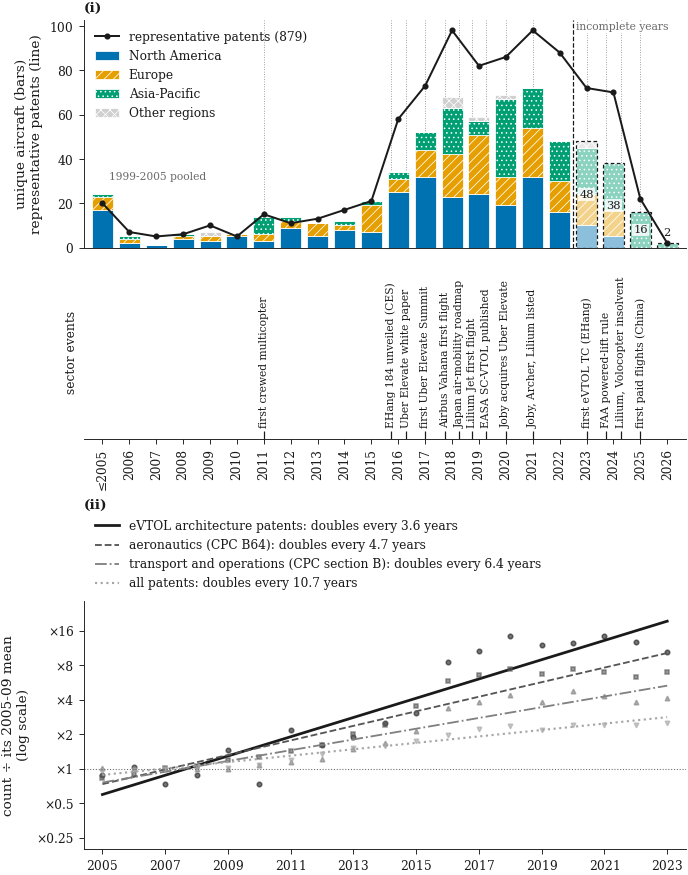

In [12]:
W, _ = style.size(cfg, 'full')
fig, (ax, strip, ax2) = plt.subplots(3, 1, figsize=(W, 8.0), gridspec_kw=dict(height_ratios=[2.3, 1.75, 2.5]), constrained_layout=True)
plots.region_stack(ax, t[regs], line=t['patents representative'], line_label=f"representative patents ({thin(n_rep)})",
                   incomplete=incomplete, pooled_first='1999-2005 pooled')
ax.set_xticks([]); ax.set_ylabel('unique aircraft (bars)\nrepresentative patents (line)')
first_inc = years.index(incomplete[0])
ax.axvline(first_inc - 0.5, color=style.INK, linewidth=0.8, linestyle='--')
ax.text(first_inc - 0.4, ax.get_ylim()[1] * 0.99, 'incomplete years', va='top', fontsize=7, color=style.MUTED,
        bbox=dict(fc='white', ec='none', pad=0.5))
ax.legend(loc='upper left'); style.mark(ax, '(i)')
plots.event_strip(strip, events, years, parent=ax)
strip.set_xlim(ax.get_xlim())
strip.set_xticks(range(len(years)), [('≤2005' if y == 2005 else str(y)) for y in years], rotation=90)
shown = ['evtol_families', 'b64', 'secb', 'all']                    # the aircraft series is fitted but not drawn
plots.growth_fits(ax2, {k: ser[k] for k in shown}, fits, NAMES, 2005, 2023)
ax2.set_xticks(range(2005, 2024, 2))
ax2.legend(loc='lower left', bbox_to_anchor=(0, 1.0)); style.mark(ax2, '(ii)', lines_up=4.7)
plt.show()

In [13]:
fig1_data = t.join(pd.DataFrame({NAMES[k]: ser[k] for k in shown}).loc[2005:2023], how='left')
save.figure(fig, cfg, 'q1', 'fig_01_filings_per_year', data=fig1_data,
            caption="(i) unique aircraft, counted once, by the priority year of their first patent (later patents on the same aircraft are not counted again), per year and applicant region, with the representative patents as a line and the dated sector events under the bars. (ii) how fast each series grows: eVTOL architecture patents, eVTOL unique aircraft and three worldwide baselines (WIPO), each relative to its own 2005-09 average on a log axis, with its fitted line over 2005-2023. (i) filings per priority year, by applicant region; (ii) eVTOL's share of aeronautics, of section B and of all patenting worldwide, relative to its 2005-09 share.",
            source='PatSeer (snapshot 2026-06-08) · human labelling · sector events: the author\'s dated list (checked 2026-09-23) · baselines: PatSeer worldwide simple families for CPC B64 and CPC section B, WIPO patent families by origin (indicator 6a) for all patents, exported 2026-09-25',
            unit='(i) unique aircraft and representative patents per priority year; (ii) patent families per priority year, each relative to its own 2005-09 mean',
            read='(i) Bars: unique aircraft by the priority year of their first patent, stacked by applicant region; the first bar holds 1999-2005. A year is faded with a dashed outline while the snapshot is less than the 90th-percentile publication lag (3 years) after its end: it will still grow, and its bar total is printed on it. Line: the representative patents. Strip: dated sector events; an event stands on its calendar year. (ii) Equal slopes are equal growth rates; points are yearly counts, lines are least-squares fits of log count on year over 2005-2023.',
            panels={'(i)': 'filings per priority year by region', '(ii)': 'growth of each series, log axis'})
plt.close(fig)

### Figure 2 — the class mix against the evtol.news directory

The 12 classes are folded to the five of the directory with the fold of the yaml (`analysis.class_fold`); the directory is counted by development year. Both sources use the same windows (the partial window is not drawn). The fold of the document sent Stopped/Slowed Rotor Wing to Electric Rotorcraft; the ruling of 2026-10-01 sends it to Lift + Cruise. `v_doc` re-folds with the document's own rule, to prove the table reproduces the document, and `changed_cells` then marks the cells the ruling moved.

In [14]:
def class_mix(frame):
    L = frames.evtolnews_long(frame, cfg, WIN)
    names = {'patent': 'patent corpus (unique aircraft, priority year)', 'directory': 'evtol.news directory (aircraft, development year)'}
    rows = []
    for src in ('patent', 'directory'):
        for w in WIN_NAMES:
            sw = L[(L['source'] == src) & (L['window'] == w)]
            for c in frames.CLASS5_ORDER:
                k = int((sw['class5'] == c).sum())
                rows.append({'source': names[src], 'window': w, 'class': frames.CLASS5_NAMES[c], 'code': c, 'aircraft': k,
                             'window total': len(sw), 'share': round(k / len(sw), 3) if len(sw) else np.nan})
    return pd.DataFrame(rows)

mix = class_mix(v)                                                        # current fold: SRW -> LC
v_doc = frames.base(ds, cfg, fold={**cfg.analysis['class_fold'], 'SRW': 'ER'})   # the document's fold
mix_doc = class_mix(v_doc)
KEY = ['source', 'window', 'code']
verify(mix_doc, 'la_evtolnews_check', 'la_evtolnews_check, document fold, SRW to ER', key=KEY)                            # the document's own fold reproduces the document
verify(mix, 'la_evtolnews_check', 'la_evtolnews_check, current fold (SRW to LC)', key=KEY, expected=checks.changed_cells(mix, mix_doc, KEY))

,"la_evtolnews_check, document fold, SRW to ER"
table,"la_evtolnews_check, document fold, SRW to ER"
rows (notebook | document),50 | 50
cells compared,200
matched,200
expected differences,0
differences,0
status,match


,"la_evtolnews_check, current fold (SRW to LC)"
table,"la_evtolnews_check, current fold (SRW to LC)"
rows (notebook | document),50 | 50
cells compared,200
matched,188
expected differences,12
differences,0
status,match except expected


,row,column,notebook,document,label
0,"(patent corpus (unique aircraft, priority year), 2016-19, lc)",aircraft,51.000,48,expected: SRW→LC ruling 2026-10-01
1,"(patent corpus (unique aircraft, priority year), 2016-19, lc)",share,0.242,0.227,expected: SRW→LC ruling 2026-10-01
2,"(patent corpus (unique aircraft, priority year), 2016-19, er)",aircraft,4.000,7,expected: SRW→LC ruling 2026-10-01
3,"(patent corpus (unique aircraft, priority year), 2016-19, er)",share,0.019,0.033,expected: SRW→LC ruling 2026-10-01
4,"(patent corpus (unique aircraft, priority year), 2020-23, lc)",aircraft,78.000,75,expected: SRW→LC ruling 2026-10-01
5,"(patent corpus (unique aircraft, priority year), 2020-23, lc)",share,0.329,0.316,expected: SRW→LC ruling 2026-10-01
6,"(patent corpus (unique aircraft, priority year), 2020-23, er)",aircraft,1.000,4,expected: SRW→LC ruling 2026-10-01
7,"(patent corpus (unique aircraft, priority year), 2020-23, er)",share,0.004,0.017,expected: SRW→LC ruling 2026-10-01
8,"(patent corpus (unique aircraft, priority year), 2024-26 (partial), lc)",aircraft,18.000,16,expected: SRW→LC ruling 2026-10-01
9,"(patent corpus (unique aircraft, priority year), 2024-26 (partial), lc)",share,0.321,0.286,expected: SRW→LC ruling 2026-10-01


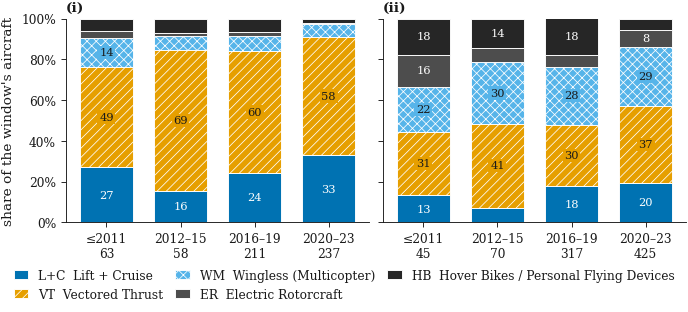

In [15]:
spec = {'LC': ('SLC', 'L+C'), 'VT': ('TR', 'VT'), 'WM': ('MR', 'WM'), 'ER': ('RC', 'ER'), 'HB': ('HB', 'HB')}
W5 = [w for w in WIN_NAMES if 'partial' not in w]
LABEL = {'<= 2011': '≤2011', '2012-15': '2012–15', '2016-19': '2016–19', '2020-23': '2020–23'}
fig, axes = plt.subplots(1, 2, figsize=(W, 2.9), sharey=True, constrained_layout=True)
for ax, (src, mark) in zip(axes, [('patent corpus (unique aircraft, priority year)', '(i)'), ('evtol.news directory (aircraft, development year)', '(ii)')]):
    s = mix[(mix['source'] == src) & mix['window'].isin(W5)]
    share = s.pivot(index='window', columns='code', values='share').reindex(index=W5, columns=frames.CLASS5_ORDER)
    total = s.groupby('window')['window total'].first().reindex(W5)
    plots.folded_bars(ax, share.rename(index=LABEL), spec, totals=[int(x) for x in total])
    style.mark(ax, mark)
axes[0].set_ylabel("share of the window's aircraft")
handles = axes[0].get_legend_handles_labels()[0]
fig.legend(handles, [f"{spec[c][1]}  {frames.CLASS5_NAMES[c]}" for c in frames.CLASS5_ORDER], loc='outside lower center', ncol=3,
           handlelength=1.2, columnspacing=1.0)
plt.show()

In [16]:
fig2_data = mix[mix['window'].isin(W5)]
n_p = int(fig2_data[(fig2_data['source'].str.startswith('patent')) & (fig2_data['code'] == 'LC')]['window total'].sum())
n_d = int(fig2_data[(fig2_data['source'].str.startswith('evtol')) & (fig2_data['code'] == 'LC')]['window total'].sum())
save.figure(fig, cfg, 'q1', 'fig_02_evtolnews_check', data=fig2_data,
            caption="the class mix per window in the labelled dataset, folded to the five classes of the evtol.news directory (i), beside the directory's own mix per development-year window (ii) (evtol.news, Vertical Flight Society). Chapter 3 reads it for 3.1.",
            source='PatSeer · human labelling, folded to the five classes of the directory (analysis.class_fold) · evtol.news directory (Vertical Flight Society), crawled 2026-09-17, development year read by two readers',
            unit=f"unique aircraft by priority-year window (i), directory aircraft by development-year window (ii); the aircraft under each bar are printed with its window: {thin(n_p)} aircraft with a class in (i), {thin(n_d)} dated aircraft in (ii) of 1 229 listed",
            read='Each bar is 100 % of one window; segments print their share in percent (segments under 8 % carry no number). The class fold: L+C = Lift + Cruise (with Stopped/Slowed Rotor Wing since 2026-10-01), VT = every tilting class (Tilt Propulsor, CVT, Tilt Wing, Tilt Body, Pitch-to-Cruise) and Deflected Slipstream, WM = Multirotor, ER = Rotorcraft, HB = Hoverbike and Personal Flying Vehicle. The partial window 2024-26 is not drawn.',
            panels={'(i)': 'labelled dataset, priority-year windows', '(ii)': 'evtol.news directory, development-year windows'})
plt.close(fig)

### Table 1 and Figure 3 — the patent clock against the market clock

For the index firms of the AAM Reality Index (May 2026 release) that file in this corpus: first, peak and last priority year of the firm's unique aircraft, and the first flight and the entry into service the index states (the earliest year printed where a firm lists several vehicles). The gaps count from the firm's first patent IN THIS CORPUS, so they are floors: a firm that flew before it appears here prints a negative gap.

In [17]:
tl = frames.ari_timeline(v, cfg)
verify(tl, 'la_ari_timeline', key=['company'])
tab1 = tl[['company', 'first patent', 'first flight (ARI)', 'entry into service (ARI)', 'years to first flight', 'years to entry into service']]
tab1 = tab1.astype(object).where(tab1.notna(), '')
for c in ['first flight (ARI)', 'entry into service (ARI)', 'years to first flight', 'years to entry into service']:
    tab1[c] = tab1[c].map(lambda x: f"{x:.0f}" if x != '' else '')
save.table(tab1, cfg, 'q1', 'tab_1_ari_timeline', caption='The index firms that file in this corpus: first patent here, first flight and planned entry into service as the AAM Reality Index reports them, and the years between.',
           source='AAM Reality Index (May 2026 release: first_flight and eis fields, kept verbatim) · PatSeer · human labelling')
tab1

,la_ari_timeline
table,la_ari_timeline
rows (notebook | document),13 | 13
cells compared,169
matched,169
expected differences,0
differences,0
status,match


,company,first patent,first flight (ARI),entry into service (ARI),years to first flight,years to entry into service
0,Joby Aviation,2013,2018,,5,
1,Embraer / Eve,2018,2025,2028,7,10
2,Honda,2018,2024,2030,6,12
3,AutoFlight,2019,2022,2026,3,7
4,Volocopter,2019,2021,2027,2,8
5,Archer Aviation,2020,2023,,3,
6,Wisk Aero,2020,2025,,5,
7,Beta Technologies,2021,2020,2026,-1,5
8,Wollant Aviation,2022,2023,2026,1,4
9,Ascendance Flight Technologies,2022,2027,2029,5,7


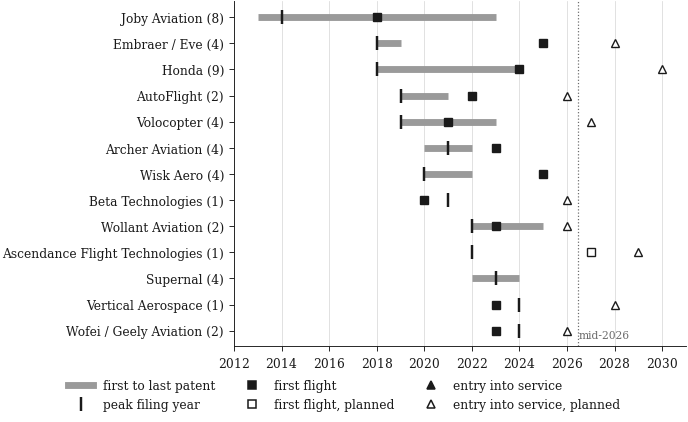

In [18]:
fig, ax = plt.subplots(figsize=(W, 3.9), constrained_layout=True)
plots.clock_rows(ax, tl, today=2026.45, planned_after=frames.ARI_RELEASE_YEAR - 1)
ax.set_xlim(2012, 2031)
ax.text(2026.5, len(tl) - 0.7, 'mid-2026', fontsize=7, color=style.MUTED)
plots.clock_legend(fig, loc='outside lower center', ncol=3)
plt.show()
save.figure(fig, cfg, 'q1', 'fig_03_ari_clock', data=tl,
            caption='the patent clock against the market clock for the AAM Reality Index firms, one row per firm.',
            source='AAM Reality Index (May 2026 release; first_flight and eis as the index prints them) · PatSeer · human labelling',
            unit='the index firms that file here (13), one row each; priority years and index years; the number after a firm is its unique aircraft in this corpus',
            read='Each row is one firm: the bar runs from its first to its last priority year in this corpus, the tick marks the year it filed most. Squares: the first flight the index reports; triangles: entry into service. An open marker is a plan (a year after the index release of 2026). Nothing here is a flight record: both market dates are the index\'s own statements, and the gap from first patent to first flight is a floor.')
plt.close(fig)

### 1.1.4 External comparison: investment and market forecasts

Disclosed funding and published market forecasts, collected for scale only (`assets/external/investment`). Funding trackers differ in scope (VFS counts eVTOL companies, McKinsey future air mobility), and the forecasts are commercial revenue projections: the comparison is by eye, never a test.

In [19]:
fund = pd.read_csv(cfg.path('sector_funding')).set_index('period')['funding_usd_bn']
fc = pd.read_csv(cfg.path('market_forecasts'))
fc[['publisher', 'value_2034_usd_bn', 'cagr_pct']]

,publisher,value_2034_usd_bn,cagr_pct
0,IMARC Group,39.00,10.50
1,Fortune Business Insights,17.39,36.76
2,Straits Research,11.60,28.56
3,The Insight Partners,5.59,26.80
4,Exactitude Consultancy,37.20,19.72


### 1.1 numbers

Every number the document's text quotes for 1.1, written as the document prints it. The first flight is a flight only if the index dates it no later than its own release (2026); a later date is a plan and is not counted.

In [20]:
flown = tl[tl['first flight (ARI)'] <= frames.ARI_RELEASE_YEAR]
gap = flown['years to first flight']
lead = gap[gap > 0].median()
y18 = int(fpy.loc[2018, 'unique aircraft'])
ge = lambda a, w: ratios[(ratios['eVTOL counted as'] == 'eVTOL architecture patents') & (ratios['against'] == a) & (ratios['window'] == w)].iloc[0]
dbl = lambda key: rates[(rates['key'] == key) & (rates['primary'])].iloc[0]['doubling time (years)']
main, sens = ge('aeronautics (CPC B64)', '2005–2023'), ge('aeronautics (CPC B64)', '2005–2019')
N1 = {
    'tk_y2018': str(y18), 'sm_pat_2018': str(int(fpy.loc[2018, 'patents representative'])),
    'sm_turn_draws': thin(growth.TURNING_DRAWS),
    'sm_turn_pat_year': str(TP['representative patents']['break']), 'sm_turn_pat_x': f"{TP['representative patents']['jump']:.1f}",
    'sm_turn_pat_boot': pct(TP['representative patents']['share']),
    'sm_turn_pat_prev': str(int(fpy.loc[TP['representative patents']['break'] - 1, 'patents representative'])),
    'sm_turn_pat_prev_year': str(TP['representative patents']['break'] - 1),
    'sm_turn_pat_after': str(int(fpy.loc[TP['representative patents']['break'], 'patents representative'])),
    'sm_turn_ac_year': str(TP['unique aircraft']['break']), 'sm_turn_ac_x': f"{TP['unique aircraft']['jump']:.1f}",
    'sm_turn_ac_lo': str(TP['unique aircraft']['lo']), 'sm_turn_ac_hi': str(TP['unique aircraft']['hi']),
    'sm_turn_sh_lo': str(TP['aircraft per 1 000 B64']['lo']), 'sm_turn_sh_hi': str(TP['aircraft per 1 000 B64']['hi']),
    'sm_g_fam_dbl': f"{dbl('evtol_families'):.1f}", 'sm_g_b64_dbl': f"{dbl('b64'):.1f}",
    'sm_g_secb_dbl': f"{dbl('secb'):.1f}", 'sm_g_all_dbl': f"{dbl('all'):.1f}",
    'sm_gr_fam_b64': f"{main['times as fast']:.2f}", 'sm_gr_fam_b64_ci': main['95 % interval'],
    'sm_gr_fam_all': f"{ge('all patents', '2005–2023')['times as fast']:.2f}",
    'sm_gr_fam_b64_19': f"{sens['times as fast']:.2f}", 'sm_gr_fam_b64_19_ci': sens['95 % interval'],
    'sm_gr_fam_b64_19_va': 'the edge still holds' if sens['reading'] == 'faster' else
                           'it can no longer be told from equal pace' if sens['reading'] == 'cannot be told apart' else 'eVTOL is slower',
    'sm_ff_flown': str(len(flown)), 'sm_ff_before': str(int((gap > 0).sum())), 'sm_ff_lead': f"{lead:.0f}",
    'sm_ff_visible': f"{lead - int(N0['lag_p90']):.0f}", 'tk_ari_timeline_n': str(len(tl)),
    'sm_ext_fund_1020': f"{fund['2010-2020']:.1f}", 'sm_ext_fund_2021': f"{fund['2021']:.1f}", 'sm_ext_fund_2023': f"{fund['2023']:.1f}",
    'sm_ext_fc_n': str(len(fc)), 'sm_ext_fc_min': f"{fc['value_2034_usd_bn'].min():.1f}", 'sm_ext_fc_max': f"{fc['value_2034_usd_bn'].max():.1f}",
    'sm_ext_fc_cagr_min': f"{fc['cagr_pct'].min():.1f}", 'sm_ext_fc_cagr_max': f"{fc['cagr_pct'].max():.1f}",
}
numbers_check(N1)

,name,notebook,document,match
0,tk_y2018,68,68,yes
1,sm_pat_2018,98,98,yes
2,sm_turn_draws,2 000,2 000,yes
3,sm_turn_pat_year,2016,2016,yes
4,sm_turn_pat_x,3.4,3.4,yes
5,sm_turn_pat_boot,90 %,90 %,yes
6,sm_turn_pat_prev,21,21,yes
7,sm_turn_pat_prev_year,2015,2015,yes
8,sm_turn_pat_after,58,58,yes
9,sm_turn_ac_year,2017,2017,yes


## 1.2 — What share of the patented aircraft is still protected, and does it differ between classes?

#### Method

**Objective.** What share of the aircraft is still protected, and whether it differs between architecture classes. It matters because a class whose patents lapse faster may be a class firms are giving up, which bears on the dominant-design question of chapter 3.


**Data and unit of analysis.** Unique aircraft with a priority year of 2019 or earlier. A patent is **in force** when its PatSeer legal status at the snapshot (2026-06-08) is active: granted and kept alive, or an application still under examination. It is **inactive** when the status reads lapsed for non-payment, expired, withdrawn or surrendered, or refused. An aircraft is out of force when every one of its patents is inactive; one patent in force keeps it in force. The cut is 2019 because 97.7 % of the 781 dated grants arrive within seven years of priority, while 56.5 % of 2023 families (three years after priority), and 4.6 % of 2020 families, are still under examination (published, but neither granted nor refused). Aircraft filed after 2019 are left out because most have not yet been decided (21.8 % of the 2020-23 families are still undecided), so they would count as protected only because no decision exists yet.

**Procedure.** Figure 4 gives the share out of force per class.

**Scientific grounds.** The out-of-force share already differs between classes in the data; a chi-square test of class against out of force (statistics box) says whether a difference of that size can arise from small class counts alone, and only if it cannot is a class difference claimed, counting a patent that names several aircraft for every aircraft it names. A detected difference is then put to two checks: the same test on the aircraft filed at the US office alone, because offices lapse at different rates (an international application ends as inactive once it passes into national filings), and the same test without the largest filer; and it is re-read with a patent that names several aircraft counted for its first aircraft only.

**Assumptions and limits.** Legal status is a snapshot: it says whether an aircraft has lapsed, not when. The dated legal events in the PatSeer export could turn this alive-or-dead snapshot into a time to abandonment per class; they are left unread. Out of force refers only to the patents in this dataset: a design could still be protected by a patent outside it, although that is not expected, and for the question asked here, whether the labelled dataset's own patents are let go, this is the relevant reading.

### 1.2.1 The seven-year rule, measured

97.7 % of the dated grants arrive within seven years of priority, and the share of families still pending collapses at the rule's boundary. Read from the author's checks of the PatSeer export (`assets/external/lapse_check`).

In [21]:
lagsum = pd.read_csv(cfg.path('grant_lag'), index_col=0)['value']
status = pd.read_csv(cfg.path('grant_status_by_year'))
rows = [('dated grants in the corpus', f"{int(lagsum['with_grant_date']):d}"),
        ('median priority-to-grant lag (years)', f"{lagsum['median_lag_years']:.1f}"),
        ('90th percentile lag (years)', f"{lagsum['p90_lag_years']:.1f}"),
        ('grants arriving within 7 years of priority', f"{lagsum['pct_granted_within_7y']:.1f} %")]
for y in range(2019, 2024):
    rows.append((f'families still pending, {y} cohort', f"{float(status.loc[status['priority_year'] == y, 'pending_pct'].iloc[0]):.1f} %"))
span = status[status['priority_year'].between(2020, 2023)]
rows.append(('families still pending, 2020-23 cohort', f"{100 * span['pending'].sum() / span['n'].sum():.1f} %"))
lapse = pd.DataFrame(rows, columns=['measure', 'value'])
verify(lapse, 'la_lapse_check', key=['measure'])
lapse

,la_lapse_check
table,la_lapse_check
rows (notebook | document),10 | 10
cells compared,10
matched,10
expected differences,0
differences,0
status,match


,measure,value
0,dated grants in the corpus,781
1,median priority-to-grant lag (years),3.1
2,90th percentile lag (years),5.3
3,grants arriving within 7 years of priority,97.7 %
4,"families still pending, 2019 cohort",4.0 %
5,"families still pending, 2020 cohort",4.6 %
6,"families still pending, 2021 cohort",10.0 %
7,"families still pending, 2022 cohort",23.8 %
8,"families still pending, 2023 cohort",56.5 %
9,"families still pending, 2020-23 cohort",21.8 %


### 1.2.2 Aircraft with no patent in force

An aircraft is out of force only when EVERY patent linked to it reads INACTIVE at the snapshot: its own primary patent and every duplicate that points at it (`frames.force_frame`). Priority year 2019 or earlier, aircraft with a class. A class with ten or more aircraft enters the chi-square test of class against out of force (`lib.association.chi2_test`); the same test is repeated counting a patent that names several aircraft for its first aircraft only.

In [22]:
w = frames.force_frame(ds, v)                                     # priority <= 2019; out = no linked patent in force
g = w.groupby('topType').agg(**{'unique aircraft': ('aircraft_id', 'size'), 'out of force': ('out', 'sum'), '_old': ('lapsed', 'mean')})
g['out of force share'] = (g['out of force'] / g['unique aircraft']).round(2)
g['out of force, primary patent only'] = g['_old'].round(2)
g['class'] = [style.cls(c).name for c in g.index]
force = g.sort_values(['unique aircraft', 'class'], ascending=[False, True]).reset_index().rename(columns={'topType': 'code'})
force = force[['class', 'code', 'unique aircraft', 'out of force', 'out of force share', 'out of force, primary patent only']]
tot = pd.DataFrame([{'class': 'all classes', 'code': 'ALL', 'unique aircraft': len(w), 'out of force': int(w['out'].sum()),
                     'out of force share': round(float(w['out'].mean()), 2),
                     'out of force, primary patent only': round(float(w['lapsed'].mean()), 2)}])
force = pd.concat([force, tot], ignore_index=True)
RENAME = {'Tilt Rotor': 'Tilt Propulsor'}
verify(force.drop(columns='code'), 'la_force_aircraft', key=['class'], rename=RENAME)
force

,la_force_aircraft
table,la_force_aircraft
rows (notebook | document),13 | 13
cells compared,52
matched,52
expected differences,0
differences,0
status,match


,class,code,unique aircraft,out of force,out of force share,"out of force, primary patent only"
0,Tilt Propulsor,TR,90,31,0.34,0.38
1,Lift + Cruise,SLC,74,39,0.53,0.53
2,Combined Vectored Thrust,CVT,43,23,0.53,0.56
3,Tilt Wing,TW,33,13,0.39,0.39
4,Multirotor,MR,29,9,0.31,0.45
5,Hoverbike,HB,17,7,0.41,0.41
6,Tilt Body,TB,16,10,0.62,0.62
7,Pitch-to-Cruise,PTC,14,3,0.21,0.21
8,Rotorcraft,RC,7,4,0.57,0.57
9,Personal Flying Vehicle,PFV,5,3,0.60,0.60


In [23]:
w_first = frames.force_frame(ds, v, first_only=True).set_index('aircraft_id')['out']
w['out_first'] = w['aircraft_id'].map(w_first).astype(bool)               # a multi-target duplicate linked to its first target only
tested = force.loc[force['unique aircraft'] >= frames.FORCE_TEST_MIN, 'code']
big = w[w['topType'].isin(tested)]
def class_test(frame, col):
    table = pd.crosstab(frame['topType'], frame[col])
    return association.chi2_test(table.values)['p'], int(table.shape[0])
p_all, k_tested = class_test(big, 'out')
p_first, _ = class_test(big, 'out_first')
pd.DataFrame({'reading': ['every linked patent INACTIVE', 'multi-target duplicates to the first target only'],
              'classes tested': k_tested, 'p': [p_all, p_first]})

,reading,classes tested,p
0,every linked patent INACTIVE,8,0.042881
1,multi-target duplicates to the first target only,8,0.079099


### 1.2.3 Does the class difference survive the filing office?

Two checks on the difference between classes: without the largest filer (Bell / Textron) and within the US office alone; then the office split itself (the US against the rest, with WO and CN singled out), and what the patents at each office are.

In [24]:
meta = v.drop_duplicates('aircraft_id').set_index('aircraft_id')[['firm', 'pub_office', 'legal_status_raw']]
wo = w.join(meta, on='aircraft_id')
wo['status'] = wo['legal_status_raw'].fillna('').astype(str)
def class_p(x):
    big_ = x[x['topType'].isin(x['topType'].value_counts()[lambda s: s >= frames.FORCE_TEST_MIN].index)]
    p, k = class_test(big_, 'out')
    return p, len(big_), k
rows = []
for reading, x in [('all aircraft', wo), ('without Bell / Textron', wo[~wo['firm'].astype(str).str.contains('Bell')]),
                   ('US office only', wo[wo['pub_office'] == 'US'])]:
    p, n_, k = class_p(x)
    rows.append({'reading': reading, 'aircraft': n_, 'classes tested': k, 'out of force share': round(float(x['out'].mean()), 2), 'class p': round(p, 3)})
for reading, x in [('filed at the US office', wo[wo['pub_office'] == 'US']), ('filed elsewhere', wo[wo['pub_office'] != 'US']),
                   ('filed as WO (international)', wo[wo['pub_office'] == 'WO']), ('filed at CN', wo[wo['pub_office'] == 'CN'])]:
    rows.append({'reading': reading, 'aircraft': len(x), 'classes tested': None, 'out of force share': round(float(x['out'].mean()), 2), 'class p': None})
mr = wo[wo['topType'] == 'MR']
rows.append({'reading': 'Multirotor, multi-target duplicates to first target only', 'aircraft': len(mr), 'classes tested': None,
             'out of force share': round(float(mr['out_first'].mean()), 2), 'class p': None})
for reading, x, hit in [('WO, expired', wo[wo['pub_office'] == 'WO'], lambda s: s.eq('INACTIVE - EXPIRED')),
                        ('CN, withdrawn or refused', wo[wo['pub_office'] == 'CN'], lambda s: s.str.contains('WITHDRAWN|REFUSED')),
                        ('US, granted and in force', wo[wo['pub_office'] == 'US'], lambda s: s.eq('ACTIVE - GRANTED'))]:
    rows.append({'reading': reading, 'aircraft': len(x), 'classes tested': None, 'out of force share': int(hit(x['status']).sum()), 'class p': None})
office = pd.DataFrame(rows)
verify(office, 'la_force_office_check', key=['reading'])
office

,la_force_office_check
table,la_force_office_check
rows (notebook | document),11 | 11
cells compared,44
matched,44
expected differences,0
differences,0
status,match


,reading,aircraft,classes tested,out of force share,class p
0,all aircraft,316,8.0,0.43,0.043
1,without Bell / Textron,279,8.0,0.46,0.016
2,US office only,209,7.0,0.31,0.432
3,filed at the US office,228,NaN,0.31,NaN
4,filed elsewhere,104,NaN,0.69,NaN
5,filed as WO (international),16,NaN,0.94,NaN
6,filed at CN,22,NaN,0.91,NaN
7,"Multirotor, multi-target duplicates to first target only",29,NaN,0.41,NaN
8,"WO, expired",16,NaN,16.00,NaN
9,"CN, withdrawn or refused",22,NaN,19.00,NaN


### Figure 4 — aircraft with no patent in force, per class

One bar per class with ten or more aircraft (colour and hatch of the class), the share out of force with its n; the dash is the earlier reading (the first patent alone); the dashed line is all classes.

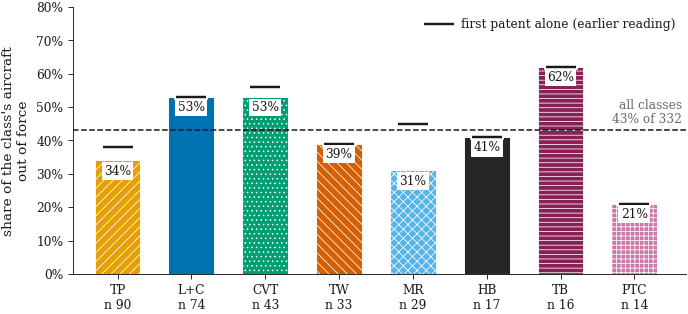

In [25]:
fd = force[(force['unique aircraft'] >= frames.FORCE_TEST_MIN) & (force['code'] != 'ALL')]
fig, ax = plt.subplots(figsize=(W, 2.9), constrained_layout=True)
plots.class_value_bars(ax, list(fd['code']), fd['out of force share'].tolist(), fd['unique aircraft'].astype(int).tolist(),
                       marks=fd['out of force, primary patent only'].tolist(), mark_label='first patent alone (earlier reading)',
                       overall=float(w['out'].mean()), overall_label=f"all classes\n{w['out'].mean():.0%} of {len(w)}")
ax.set_ylabel("share of the class's aircraft\nout of force"); ax.set_ylim(0, 0.8)
ax.legend(loc='upper right')
plt.show()

In [26]:
save.figure(fig, cfg, 'q1', 'fig_04_force_aircraft', data=fd,
            caption='unique aircraft with no patent left in force, per architecture class, priority year 2019 or earlier.',
            source='PatSeer legal status at the snapshot (2026-06-08) · human labelling (class, duplicates)',
            unit=f"unique aircraft with priority year 2019 or earlier, classes of {frames.FORCE_TEST_MIN} or more ({len(fd)} classes, {int(fd['unique aircraft'].sum())} of {len(w)} aircraft); share of the class",
            read=f"An aircraft is out of force only when none of its patents is in force. Bar: share of the class's aircraft out of force (n under the class); black dash across a bar: the share when only the aircraft's first patent is read; dashed line: all classes. Class against out of force over the {k_tested} classes drawn: chi-square p = {p_all:.3f}; counting a patent that names several aircraft for its first aircraft only: p = {p_first:.3f}.")
plt.close(fig)

### 1.2 numbers

In [27]:
fa = lambda c: force.loc[force['class'] == c, 'out of force share'].iloc[0]
of = lambda r, c='out of force share': office.loc[office['reading'] == r, c].iloc[0]
lp = lambda m: lapse.loc[lapse['measure'] == m, 'value'].iloc[0]
N2 = {
    'sm_fa_share': pct(fa('all classes')), 'sm_fa_cvt': pct(fa('Combined Vectored Thrust')), 'sm_fa_slc': pct(fa('Lift + Cruise')),
    'sm_fa_tr': pct(fa('Tilt Propulsor')), 'sm_fa_mr': pct(fa('Multirotor')),
    'sm_fa_mr_first': pct(of('Multirotor, multi-target duplicates to first target only')),
    'sm_fa_p': f"{p_all:.3f}", 'sm_fa_p_sens': f"{p_first:.3f}",
    'sm_fo_us': pct(of('filed at the US office')), 'sm_fo_else': pct(of('filed elsewhere')),
    'sm_fo_wo': pct(of('filed as WO (international)')), 'sm_fo_cn': pct(of('filed at CN')),
    'sm_fo_p_us': f"{of('US office only', 'class p'):.2f}",
    'sm_fo_why_wo_n': str(int(of('WO, expired', 'aircraft'))),
    'sm_fo_why_cn_k': str(int(of('CN, withdrawn or refused'))), 'sm_fo_why_cn_n': str(int(of('CN, withdrawn or refused', 'aircraft'))),
    'sm_fo_why_us_k': str(int(of('US, granted and in force'))), 'sm_fo_why_us_n': str(int(of('US, granted and in force', 'aircraft'))),
    'sm_lapse_grants': lp('dated grants in the corpus'), 'sm_lapse_7y': lp('grants arriving within 7 years of priority'),
    'sm_lapse_p2020': lp('families still pending, 2020 cohort'), 'sm_lapse_p2023': lp('families still pending, 2023 cohort'),
    'sm_lapse_p2020_23': lp('families still pending, 2020-23 cohort'),
}
numbers_check(N2)

,name,notebook,document,match
0,sm_fa_share,43 %,43 %,yes
1,sm_fa_cvt,53 %,53 %,yes
2,sm_fa_slc,53 %,53 %,yes
3,sm_fa_tr,34 %,34 %,yes
4,sm_fa_mr,31 %,31 %,yes
5,sm_fa_mr_first,41 %,41 %,yes
6,sm_fa_p,0.043,0.043,yes
7,sm_fa_p_sens,0.079,0.079,yes
8,sm_fo_us,31 %,31 %,yes
9,sm_fo_else,69 %,69 %,yes


## 1.3 — How faithfully do the patented aircraft describe the aircraft that get built?

#### Method

**Objective.** Whether the patent drawings describe the aircraft that get built, and whether the aircraft public sources cover stand for the rest of the labelled dataset.


**Data and unit of analysis.** Unique aircraft that can be linked to an outside source. Only an aircraft with a real product name can be matched to its evtol.news page (Figure 5); the others carry a name generated for this study. TRL, NASA's Technology Readiness Level (1-2 on paper, 3-5 components tested, 6-7 full-size prototype flown, 8-9 certified), was assessed per aircraft from public evidence (evtolindex.org, evtol.news, company statements); an aircraft no public source follows is set at TRL 2, since its patent is itself an idea on paper.

**Procedure.** Table 2 compares the label's architecture class with the public aircraft's class and with the class the patent text states, two at a time. Table 3 reads TRL per class. Table 4 and Table 5 compare the aircraft above TRL 2, and those of the 18 AAM Reality Index firms, with the rest on six attributes.

**Scientific grounds.** 87 of 97 is a sample, not the whole labelled dataset, so the agreement it shows is not exactly the agreement the unmatched aircraft would show; each agreement share therefore comes with a 95 % interval, the range within which the true agreement for the aircraft not matched plausibly lies (Wilson interval, statistics box), and without it the share could not be generalised beyond the 97 aircraft it was read on. The six attributes use chi-square for the categories (class, region, window, filer type) and Mann-Whitney for the numbers (priority year, propulsor units); see the statistics box.

**Assumptions and limits.** The matched aircraft are not a random sample: most come from firms with a public product. Their interval therefore says how precise the count is, not how well the whole labelled dataset matches the built aircraft. TRL above 2 is a floor. The TRL values and the development years of the evtol.news aircraft were extracted by a language model from public pages and have not yet been checked by hand; they will be checked if the results that rest on them are kept.

### 1.3.1 Names, and what a name buys

An aircraft carries a real product name when the labeller recognised it (`name_is_real`), else a name generated for this study. Only an aircraft with a real name can be matched to a public product, and the class comparison is run on the aircraft with a public counterpart (`frames.public_arch_frame`: the TRL table's `arch_match`, split by the whole-patent reading `arch_gt`).

In [28]:
pub = frames.public_arch_frame(ds)
named = v['name_is_real'].fillna(False).astype(bool)
linked = frames.linked_aircraft_ids(v, cfg)
compared = set(pub['aircraft_id'])
def name_row(label, mask, why):
    return {'aircraft': label, 'unique aircraft': int(mask.sum()), 'share of the analysis set': round(float(mask.mean()), 3),
            'linked to an evtol.news page': int(v.loc[mask, 'aircraft_id'].isin(linked).sum()),
            'compared with the public aircraft': int(v.loc[mask, 'aircraft_id'].isin(compared).sum()),
            'filed by a named organisation': int(v.loc[mask, 'named'].sum()), 'why': why}
coverage = pd.DataFrame([name_row('carry a real product name', named, 'the labeller recognised the aircraft and NAME_DECISIONS.csv records the product name'),
                         name_row('carry a generated identifier', ~named, 'no public product was recognised behind the drawing, so no match could be attempted'),
                         name_row('all unique aircraft', named | ~named, '')])
verify(coverage, 'la_name_coverage', key=['aircraft'])
coverage

,la_name_coverage
table,la_name_coverage
rows (notebook | document),3 | 3
cells compared,18
matched,18
expected differences,0
differences,0
status,match


,aircraft,unique aircraft,share of the analysis set,linked to an evtol.news page,compared with the public aircraft,filed by a named organisation,why
0,carry a real product name,97,0.155,94,97,91,the labeller recognised the aircraft and NAME_DECISIONS.csv records the product name
1,carry a generated identifier,530,0.845,0,0,350,"no public product was recognised behind the drawing, so no match could be attempted"
2,all unique aircraft,627,1.000,94,97,441,


### Figure 5 — unique aircraft by name and public match

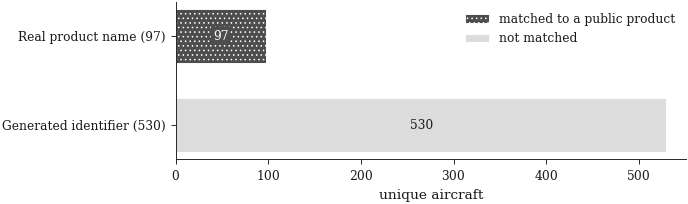

In [29]:
cr = coverage.set_index('aircraft')
real, gen = cr.loc['carry a real product name'], cr.loc['carry a generated identifier']
m_ = [int(real['compared with the public aircraft']), int(gen['compared with the public aircraft'])]
u_ = [int(real['unique aircraft']) - m_[0], int(gen['unique aircraft']) - m_[1]]
fig, ax = plt.subplots(figsize=(W, 1.9), constrained_layout=True)
plots.split_hbars(ax, [f"Real product name ({int(real['unique aircraft'])})", f"Generated identifier ({int(gen['unique aircraft'])})"],
                  m_, u_, 'matched to a public product', 'not matched')
ax.set_xlabel('unique aircraft'); ax.legend(loc='upper right')
plt.show()
save.figure(fig, cfg, 'q1', 'fig_05_name_coverage', data=coverage.drop(columns='why'),
            caption='Unique aircraft by name: the ones that carry a real product name and, of those, whether the aircraft was matched to a public product; the ones that carry a name generated for this study.',
            source='human labelling (aircraft names, NAME_DECISIONS) · evtol.news (public aircraft)',
            unit='unique aircraft (627), no time axis, counts',
            read='One bar per kind of name: a real product name recognised by the labeller, or a generated identifier. Within a bar, the dark hatched segment is the aircraft matched to a public product and compared with it, the light segment the rest. Only a named aircraft could be matched at all.')
plt.close(fig)

### Table 2 — three sources of a class compared two at a time

The drawing label (wizard), the patent text (whole-patent reading) and the public aircraft (evtol.news), compared on the aircraft that have a public counterpart. Each agreement share has its 95 % Wilson interval with the finite-population correction N = 627 (`lib.intervals.wilson_fpc_interval`), because 97 aircraft are a sample of the 627.

In [30]:
m = pub['match'].astype(str)
gt = pub['arch_gt'].fillna('').astype(str)
has_gt = gt.ne('')
agree = {'drawing label against the public aircraft': (int(m.isin(['yes', 'taxonomy']).sum()), len(pub)),
         'patent text against the public aircraft': (int(m.isin(['yes', 'taxonomy', 'image']).sum()), len(pub)),
         'drawing label against the patent text': (int((gt.eq(pub['topType'].astype(str)) & has_gt).sum()), int(has_gt.sum()))}
WHY = ['the patent describes another configuration than the one the firm built, or the drawing was misread',
       'the patent describes another configuration than the one the firm built',
       'the drawing was read as one class and the text states another']
rows = []
for (name, (k, n)), why in zip(agree.items(), WHY):
    lo, hi = intervals.wilson_fpc_interval(k, n, len(v))
    rows.append({'comparison': 'architecture class: ' + name, 'agree': k, 'of': n, 'share': round(k / n, 2),
                 '95 % interval': f"{lo:.2f}–{hi:.2f}", 'the disagreements': why})
pairwise = pd.DataFrame(rows)
PW = {'architecture class: ' + k: k for k in agree}
verify(pairwise, 'la_public_pairwise', key=['comparison'], rename=PW)
save.table(pairwise, cfg, 'q1', 'tab_2_public_pairwise', caption='Three sources of a class compared two at a time on the 97 aircraft with a public counterpart: the drawing label, the patent text, the public aircraft.',
           source='human labelling (drawing label) · whole-patent reading · evtol.news (public aircraft, matched by name)')
pairwise

,la_public_pairwise
table,la_public_pairwise
rows (notebook | document),3 | 3
cells compared,12
matched,12
expected differences,0
differences,0
status,match


,comparison,agree,of,share,95 % interval,the disagreements
0,architecture class: drawing label against the public aircraft,87,97,0.90,0.83–0.94,"the patent describes another configuration than the one the firm built, or the drawing was misread"
1,architecture class: patent text against the public aircraft,89,97,0.92,0.85–0.96,the patent describes another configuration than the one the firm built
2,architecture class: drawing label against the patent text,93,97,0.96,0.91–0.98,the drawing was read as one class and the text states another


### Table 3 — NASA TRL per class

TRL per aircraft from the TRL table (assessed from public evidence by a language model, not yet checked by hand); an aircraft no public source follows is TRL 2 by construction. Bands: 2 / 3-5 / 6-7 / 8-9.

In [31]:
t = frames.trl_frame(ds)
t['class'] = t['topType'].map(lambda c: style.cls(c).name if pd.notna(c) else 'no type')
bands = [b for b, _ in frames.TRL_BANDS]
trl = pd.crosstab(t['class'], t['band']).reindex(columns=bands, fill_value=0)
trl = trl.loc[trl.sum(axis=1).sort_values(ascending=False, kind='stable').index]
trl.insert(0, 'unique aircraft', trl.sum(axis=1))
trl['above TRL 2'] = trl['unique aircraft'] - trl['TRL 2']
trl.loc['Total'] = trl.sum()
trl['share above TRL 2'] = (trl['above TRL 2'] / trl['unique aircraft']).round(2)
trl = trl.reset_index().rename(columns={'index': 'class', 'band': 'class'}); trl.columns.name = None
verify(trl, 'a2_d15_trl_by_class', key=['class'], rename=RENAME)
save.table(trl, cfg, 'q1', 'tab_3_trl_by_class', caption='Technology readiness (NASA TRL) reached by the unique aircraft, per architecture class.',
           source='NASA TRL per aircraft (inputs/trl/aircraft_trl.csv; evtol.news, evtolindex.org, company statements) · human labelling')
trl

,a2_d15_trl_by_class
table,a2_d15_trl_by_class
rows (notebook | document),14 | 14
cells compared,98
matched,98
expected differences,0
differences,0
status,match


,class,unique aircraft,TRL 2,TRL 3-5,TRL 6-7,TRL 8-9,above TRL 2,share above TRL 2
0,Lift + Cruise,165,144,4,16,1,21,0.13
1,Tilt Propulsor,151,133,5,13,0,18,0.12
2,Combined Vectored Thrust,106,99,0,7,0,7,0.07
3,Tilt Wing,56,51,3,2,0,5,0.09
4,Multirotor,48,40,0,8,0,8,0.17
5,Pitch-to-Cruise,25,24,0,1,0,1,0.04
6,Tilt Body,24,22,2,0,0,2,0.08
7,Hoverbike,19,19,0,0,0,0,0.00
8,Personal Flying Vehicle,10,10,0,0,0,0,0.00
9,Rotorcraft,9,9,0,0,0,0,0.00


### Tables 4 and 5 — do the aircraft above TRL 2, and those of the index firms, stand for the corpus?

The subset against the rest on six attributes, one at a time: chi-square for a category (class folded to five, region, priority window, filer type), Mann-Whitney for a number (priority year, propulsor units); both from `lib.association` through `frames.representativeness`. The folded class changes under the ruling of 2026-10-01, so the rows of the folded class (and the p and the largest gap that rest on it) are the cells expected to differ; `*_doc` re-folds with the document's own rule to prove the rest.

In [32]:
tid = frames.trl_frame(ds)[['aircraft_id', 'trl']]
wt = v.merge(tid, on='aircraft_id', how='left')
above = pd.to_numeric(wt['trl'], errors='coerce').fillna(2).gt(2)
rep_trl = frames.representativeness(wt, above, 'above TRL 2', WIN_NAMES)
firms = set(frames.ari_firms(v, cfg)['company'])
rep_ari = frames.representativeness(v.copy(), v['company_canonical'].isin(firms), 'index firms', WIN_NAMES)
# the same two tables under the document's fold
wt_doc = v_doc.merge(tid, on='aircraft_id', how='left')
rep_trl_doc = frames.representativeness(wt_doc, pd.to_numeric(wt_doc['trl'], errors='coerce').fillna(2).gt(2), 'above TRL 2', WIN_NAMES)
rep_ari_doc = frames.representativeness(v_doc.copy(), v_doc['company_canonical'].isin(firms), 'index firms', WIN_NAMES)
KEY = ['attribute', 'level']
verify(rep_trl_doc, 'la_trl_representativeness', 'la_trl_representativeness, document fold', key=KEY)
verify(rep_trl, 'la_trl_representativeness', 'la_trl_representativeness, current fold', key=KEY, expected=checks.changed_cells(rep_trl, rep_trl_doc, KEY))
verify(rep_ari_doc, 'la_ari_representativeness', 'la_ari_representativeness, document fold', key=KEY)
verify(rep_ari, 'la_ari_representativeness', 'la_ari_representativeness, current fold', key=KEY, expected=checks.changed_cells(rep_ari, rep_ari_doc, KEY))

,"la_trl_representativeness, document fold"
table,"la_trl_representativeness, document fold"
rows (notebook | document),19 | 19
cells compared,209
matched,209
expected differences,0
differences,0
status,match


,"la_trl_representativeness, current fold"
table,"la_trl_representativeness, current fold"
rows (notebook | document),19 | 19
cells compared,209
matched,201
expected differences,8
differences,0
status,match except expected


,row,column,notebook,document,label
0,"(folded class, vt)",p,0.1066,0.0615,expected: SRW→LC ruling 2026-10-01
1,"(folded class, vt)",largest gap,LC (+6.4 pp),LC (+7.8 pp),expected: SRW→LC ruling 2026-10-01
2,"(folded class, lc)",rest,152,144,expected: SRW→LC ruling 2026-10-01
3,"(folded class, lc)",rest %,27.0,25.5,expected: SRW→LC ruling 2026-10-01
4,"(folded class, lc)",gap pp,6.4,7.8,expected: SRW→LC ruling 2026-10-01
5,"(folded class, er)",rest,9,17,expected: SRW→LC ruling 2026-10-01
6,"(folded class, er)",rest %,1.6,3.0,expected: SRW→LC ruling 2026-10-01
7,"(folded class, er)",gap pp,-1.6,-3.0,expected: SRW→LC ruling 2026-10-01


,"la_ari_representativeness, document fold"
table,"la_ari_representativeness, document fold"
rows (notebook | document),19 | 19
cells compared,209
matched,209
expected differences,0
differences,0
status,match


,"la_ari_representativeness, current fold"
table,"la_ari_representativeness, current fold"
rows (notebook | document),19 | 19
cells compared,209
matched,198
expected differences,11
differences,0
status,match except expected


,row,column,notebook,document,label
0,"(folded class, vt)",p,0.1511,0.1421,expected: SRW→LC ruling 2026-10-01
1,"(folded class, lc)",index firms,40.0000,39,expected: SRW→LC ruling 2026-10-01
2,"(folded class, lc)",index firms %,27.2000,26.5,expected: SRW→LC ruling 2026-10-01
3,"(folded class, lc)",rest,133.0000,126,expected: SRW→LC ruling 2026-10-01
4,"(folded class, lc)",rest %,27.7000,26.2,expected: SRW→LC ruling 2026-10-01
5,"(folded class, lc)",gap pp,-0.5000,0.3,expected: SRW→LC ruling 2026-10-01
6,"(folded class, er)",index firms,0.0000,1,expected: SRW→LC ruling 2026-10-01
7,"(folded class, er)",index firms %,0.0000,0.7,expected: SRW→LC ruling 2026-10-01
8,"(folded class, er)",rest,9.0000,16,expected: SRW→LC ruling 2026-10-01
9,"(folded class, er)",rest %,1.9000,3.3,expected: SRW→LC ruling 2026-10-01


In [33]:
VERDICT = {'matches the rest': 'no difference detected', 'does NOT match the rest': 'differs'}
def printed(rep, label):
    s = rep[rep['test'] != ''].copy()
    return pd.DataFrame({'attribute': s['attribute'], f'n {label}': s[f'n {label}'].astype(int), 'n rest': s['n rest'].astype(int),
                         'largest gap': s['largest gap'], 'test': s['test'],
                         'p': s['p'].map(lambda p: '< 0.001' if p < 0.001 else f"{p:.2f}"), 'verdict': s['verdict'].map(VERDICT)}).reset_index(drop=True)
tab4, tab5 = printed(rep_trl, 'above TRL 2'), printed(rep_ari, 'index firms')
save.table(tab4, cfg, 'q1', 'tab_4_trl_representativeness', caption='Do the aircraft above TRL 2 stand for the corpus? One test per attribute: chi-square for a category, Mann-Whitney for a number.',
           source='NASA TRL (inputs/trl/aircraft_trl.csv) · human labelling · PatSeer')
save.table(rep_trl, cfg, 'q1', 'tab_4_trl_representativeness_levels', caption='Table 4, every level of every attribute: the share of the 63 aircraft above TRL 2 and of the rest.',
           source='NASA TRL (inputs/trl/aircraft_trl.csv) · human labelling · PatSeer')
save.table(tab5, cfg, 'q1', 'tab_5_ari_representativeness', caption='Do the index-firm aircraft stand for the corpus? One test per attribute.',
           source='AAM Reality Index · human labelling · PatSeer')
save.table(rep_ari, cfg, 'q1', 'tab_5_ari_representativeness_levels', caption='Table 5, every level of every attribute: the share of the 147 aircraft of the index firms and of the rest.',
           source='AAM Reality Index · human labelling · PatSeer')
display(tab4); display(tab5)

,attribute,n above TRL 2,n rest,largest gap,test,p,verdict
0,folded class,63,564,LC (+6.4 pp),chi-square,0.11,no difference detected
1,applicant region,63,564,Asia-Pacific (-4.7 pp),chi-square,0.83,no difference detected
2,priority window,63,564,2020-23 (+12.7 pp),chi-square,0.07,no difference detected
3,filer type,63,564,Named company (+35.5 pp),chi-square,< 0.001,differs
4,priority year,63,564,median +1.0,Mann-Whitney,0.05,no difference detected
5,propulsive units,63,564,median +3.0,Mann-Whitney,< 0.001,differs


,attribute,n index firms,n rest,largest gap,test,p,verdict
0,folded class,147,480,VT (+7.3 pp),chi-square,0.15,no difference detected
1,applicant region,147,480,North America (+28.8 pp),chi-square,< 0.001,differs
2,priority window,147,480,2016-19 (+18.7 pp),chi-square,< 0.001,differs
3,filer type,147,480,Named company (+47.9 pp),chi-square,< 0.001,differs
4,priority year,147,480,median +0.0,Mann-Whitney,0.41,no difference detected
5,propulsive units,147,480,median +1.0,Mann-Whitney,< 0.001,differs


### 1.3.5 The labelled dataset against the evtol.news directory, class by class

**Question.** Does the class mix of the patented aircraft stand for the aircraft the sector announces? If not, which class makes the difference, and why?

**Method.** Both sources are counted in unique aircraft and folded to the directory's five classes (`analysis.class_fold` in the yaml: L+C → LC; TP, TW, CVT, TB, PTC, DS → VT; MR → WM; RC → ER; SRW → LC by the ruling of 2026-10-01; HB, PFV → HB). The labelled dataset is the 627 analysis aircraft (625 with a class); the directory is every evtol.news aircraft page (1 229; a page is a model or a version of it, so a family can count more than once). The two mixes are compared with a chi-square test, and each cell with its adjusted standardized residual (`lib.association.adjusted_residuals`: |r| > 1.96 marks the classes that make the difference). Shares carry a 95 % Wilson interval (`lib.intervals`).

**Why the mixes could differ — each tested by rebuilding the directory side:** (a) **domain**: the dataset keeps only electric, non-UAV aircraft, the directory keeps everything → the directory restricted to pages whose power source is not only combustion/hybrid/fuel cell and that are not cargo-only or unmanned with no capacity (`frames.directory_frame`, an approximation from the free-text spec sheet); (b) **maturity**: concept designs against flying hardware; (c) **time**: answered per window by Figure 2; (d) **patenting**: the directory pages that are linked to a patented aircraft of this dataset against those that are not. A subset whose mix matches the dataset's points at the reason.

**Caveat on (d).** The linked pages are the directory aircraft that were matched by name to a patented aircraft, so they are the named, company-backed part of the dataset (Table 2: 97 aircraft). Their class here is the DIRECTORY's own class, not the wizard label, so a match is not circular: it says the directory itself classes the patented aircraft like the dataset does. It cannot say whether unnamed patented aircraft would behave the same.

In [34]:
O5 = ['VT', 'LC', 'WM', 'ER', 'HB']
NAME5 = {'VT': 'Vectored Thrust', 'LC': 'Lift + Cruise', 'WM': 'Wingless (Multicopter)', 'ER': 'Electric Rotorcraft', 'HB': 'Hoverbike / Personal Flying Device'}
dirf = frames.directory_frame(cfg)
n_set = v['class5'].value_counts().reindex(O5, fill_value=0)              # labelled dataset, unique aircraft
n_dir = dirf['class5'].value_counts().reindex(O5, fill_value=0)           # directory, unique pages
ct = np.vstack([n_set.to_numpy(), n_dir.to_numpy()])
mix_test = association.chi2_test(ct)
resid = association.adjusted_residuals(ct)[0]                           # dataset row: + = more than expected
def ci(k, n):
    lo, hi = intervals.wilson_interval(k, n)
    return f"{lo * 100:.0f}–{hi * 100:.0f} %"
mix5 = pd.DataFrame({'class': [NAME5[c] for c in O5], 'code': O5,
                     'labelled dataset': n_set.to_numpy(), 'share in dataset': (n_set / n_set.sum()).round(3).to_numpy(),
                     'dataset 95 % interval': [ci(k, n_set.sum()) for k in n_set],
                     'evtol.news directory': n_dir.to_numpy(), 'share in directory': (n_dir / n_dir.sum()).round(3).to_numpy(),
                     'directory 95 % interval': [ci(k, n_dir.sum()) for k in n_dir],
                     'difference (points)': ((n_set / n_set.sum() - n_dir / n_dir.sum()) * 100).round(1).to_numpy(),
                     'adjusted residual': resid.round(1)})
print(f"dataset {n_set.sum()} aircraft · directory {n_dir.sum()} pages · chi-square {mix_test['chi2']:.1f}, dof {mix_test['dof']}, p {pval(mix_test['p'])}")
mix5

dataset 625 aircraft · directory 1229 pages · chi-square 203.4, dof 4, p < 0.001


,class,code,labelled dataset,share in dataset,dataset 95 % interval,evtol.news directory,share in directory,directory 95 % interval,difference (points),adjusted residual
0,Vectored Thrust,VT,366,0.586,55–62 %,426,0.347,32–37 %,23.9,9.8
1,Lift + Cruise,LC,173,0.277,24–31 %,225,0.183,16–21 %,9.4,4.6
2,Wingless (Multicopter),WM,48,0.077,6–10 %,365,0.297,27–32 %,-22.0,-10.8
3,Electric Rotorcraft,ER,9,0.014,1–3 %,86,0.070,6–9 %,-5.6,-5.1
4,Hoverbike / Personal Flying Device,HB,29,0.046,3–7 %,127,0.103,9–12 %,-5.7,-4.2


Which part of the directory looks like the dataset? The same five shares for each subset of the directory, each tested against the dataset (chi-square, 5 classes). The subset with the smallest chi-square is the one whose mix is closest to the patented aircraft.

In [35]:
subsets = {
    'labelled dataset (patented aircraft)': None,
    'directory: all pages': pd.Series(True, index=dirf.index),
    '(a) in domain: electric, crewed': dirf['in_domain'],
    '(b) concept designs': dirf['status_group'].eq('concept design'),
    '(b) flying hardware': dirf['status_group'].eq('flying hardware'),
    '(d) linked to a patent of this dataset': dirf['patented'],
    '(d) not linked to a patent': ~dirf['patented'],
}
rows = []
for name, m in subsets.items():
    k = n_set if m is None else dirf.loc[m, 'class5'].value_counts().reindex(O5, fill_value=0)
    row = {'source': name, 'n': int(k.sum())}
    for c in O5:
        row[c] = round(k[c] / k.sum(), 3)
    if m is not None:
        t = association.chi2_test(np.vstack([n_set.to_numpy(), k.to_numpy()]))
        row['chi-square vs dataset'], row['p vs dataset'] = round(t['chi2'], 1), pval(t['p'])
    rows.append(row)
why = pd.DataFrame(rows)
why

,source,n,VT,LC,WM,ER,HB,chi-square vs dataset,p vs dataset
0,labelled dataset (patented aircraft),625,0.586,0.277,0.077,0.014,0.046,NaN,NaN
1,directory: all pages,1229,0.347,0.183,0.297,0.070,0.103,203.4,< 0.001
2,"(a) in domain: electric, crewed",876,0.329,0.180,0.299,0.064,0.128,204.3,< 0.001
3,(b) concept designs,420,0.436,0.174,0.262,0.076,0.052,103.6,< 0.001
4,(b) flying hardware,247,0.211,0.291,0.364,0.045,0.089,157.1,< 0.001
5,(d) linked to a patent of this dataset,97,0.536,0.299,0.103,0.041,0.021,5.9,0.208
6,(d) not linked to a patent,1132,0.330,0.173,0.314,0.072,0.110,226.3,< 0.001


In [36]:
closest = why.dropna(subset=['chi-square vs dataset']).sort_values('chi-square vs dataset').iloc[0]
wm = why.set_index('source')['WM']
print(f"The class that makes the difference: {NAME5[O5[int(np.argmin(resid))]]} (adjusted residual {resid.min():.1f}) "
      f"and {NAME5[O5[int(np.argmax(resid))]]} (+{resid.max():.1f}).")
print(f"Multicopter share: dataset {wm.iloc[0]:.0%}, directory {wm['directory: all pages']:.0%}, in domain {wm['(a) in domain: electric, crewed']:.0%}, "
      f"flying hardware {wm['(b) flying hardware']:.0%}, linked to a patent {wm['(d) linked to a patent of this dataset']:.0%}.")
print(f"Closest directory subset to the dataset: {closest['source']} (chi-square {closest['chi-square vs dataset']}, p {closest['p vs dataset']}, n {closest['n']}).")
save.table(mix5, cfg, 'q1', 'tab_1_3_5_dataset_vs_directory',
           caption='Unique aircraft per evtol.news class in the labelled dataset and in the evtol.news directory, with 95 % Wilson intervals, the difference in points and the adjusted standardized residual of the dataset cell.',
           source='human labelling, folded by analysis.class_fold · evtol.news directory pages (crawled 2026-09-17)')
save.table(why, cfg, 'q1', 'tab_1_3_5_directory_subsets',
           caption='The class shares of each subset of the directory against the labelled dataset; chi-square of the subset against the dataset over the five classes.',
           source='evtol.news directory pages (status, power source, capacity, piloting) · patent_links.csv · human labelling')

The class that makes the difference: Wingless (Multicopter) (adjusted residual -10.8) and Vectored Thrust (+9.8).
Multicopter share: dataset 8%, directory 30%, in domain 30%, flying hardware 36%, linked to a patent 10%.
Closest directory subset to the dataset: (d) linked to a patent of this dataset (chi-square 5.9, p 0.208, n 97).


PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/q1_growth_protection_fidelity/tables/tab_1_3_5_directory_subsets.csv')

### Figure 5b — the labelled dataset against the evtol.news directory

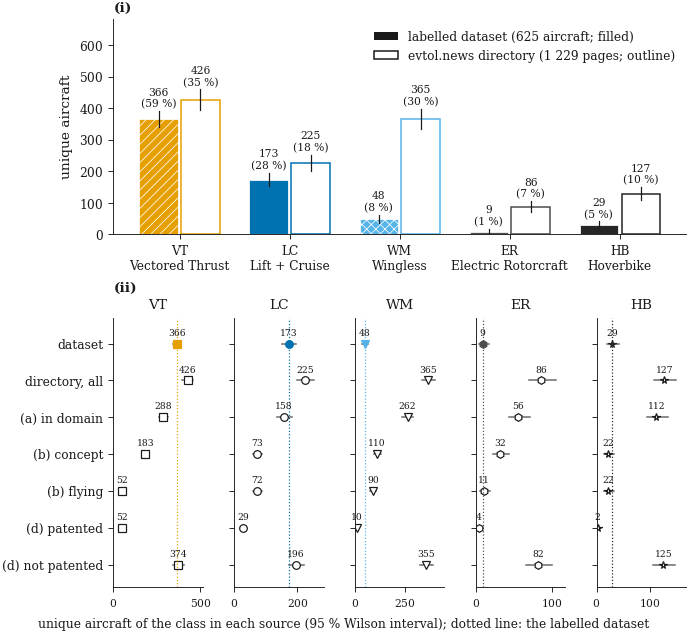

In [37]:
SPEC5 = {'LC': 'SLC', 'VT': 'TR', 'WM': 'MR', 'ER': 'RC', 'HB': 'HB'}         # the hatch/marker each class borrows (as Figure 2)
VFS5 = {'LC': 'Lift + Cruise', 'VT': 'Vectored Thrust', 'WM': 'Wingless (Multicopter)', 'ER': 'Electric Rotorcraft', 'HB': 'Hover Bikes / PFD'}
import dataclasses
spec5 = lambda c: dataclasses.replace(style.cls(SPEC5[c]), color=ts.VFS[VFS5[c]])   # thesis colour of the directory category
W, _ = style.size(cfg, 'full')
fig = plt.figure(figsize=(W, 5.8), constrained_layout=True)
gs = fig.add_gridspec(2, 5, height_ratios=[1.0, 1.25])
# (i) the two sources side by side, in number of aircraft
ax = fig.add_subplot(gs[0, :])
x = np.arange(len(O5)); bw = 0.38
for i, c in enumerate(O5):
    s = spec5(c)
    for j, (k, n, face, hatch) in enumerate([(n_set[c], n_set.sum(), s.color, s.hatch),
                                             (n_dir[c], n_dir.sum(), 'white', '')]):
        xx = x[i] + (j - 0.5) * bw
        ax.bar(xx, k, bw * 0.92, color=face, hatch=hatch, edgecolor=s.color if j else 'white', linewidth=1.0 if j else 0.5)
        lo, hi = intervals.wilson_interval(k, n)
        ax.plot([xx, xx], [lo * n, hi * n], color=style.INK, linewidth=0.8)
        ax.text(xx, hi * n + 6, f"{thin(k)}\n({k / n:.0%})".replace('%', ' %'), ha='center', va='bottom',
                fontsize=plt.rcParams['xtick.labelsize'] - 1)
ax.set_xticks(x, [f"{c}\n{NAME5[c].split(' (')[0].split(' /')[0]}" for c in O5])
ax.set_ylim(0, max(n_set.max(), n_dir.max()) * 1.6)                    # room for the legend above the labels
ax.set_ylabel('unique aircraft')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=style.INK, label=f'labelled dataset ({thin(n_set.sum())} aircraft; filled)'),
                   Patch(facecolor='white', edgecolor=style.INK, label=f'evtol.news directory ({thin(n_dir.sum())} pages; outline)')],
          loc='upper right')
style.mark(ax, '(i)')
# (ii) one panel per class: the aircraft of the class in the dataset and in each part of the directory
order = [s for s in why['source']]
ylab = ['dataset', 'directory, all', '(a) in domain', '(b) concept', '(b) flying', '(d) patented', '(d) not patented']
counts = {name: (n_set if m is None else dirf.loc[m, 'class5'].value_counts().reindex(O5, fill_value=0)) for name, m in subsets.items()}
for i, c in enumerate(O5):
    a = fig.add_subplot(gs[1, i])
    s = spec5(c)
    for r, (name, m) in enumerate(subsets.items()):
        k = counts[name]
        lo, hi = intervals.wilson_interval(k[c], k.sum())
        y = len(order) - 1 - r
        a.plot([lo * k.sum(), hi * k.sum()], [y, y], color=style.MUTED, linewidth=1)
        a.plot(k[c], y, marker=s.marker, markersize=5, linestyle='none',
               color=s.color if m is None else 'white', markeredgecolor=s.color if m is None else style.INK, markeredgewidth=0.8)
        a.annotate(thin(k[c]), (k[c], y), xytext=(0, 4), textcoords='offset points', ha='center', va='bottom',
                   fontsize=plt.rcParams['xtick.labelsize'] - 2, color=style.INK)
    a.axvline(n_set[c], color=s.color, linewidth=0.8, linestyle=':')
    a.set_yticks(range(len(order)), ylab[::-1] if i == 0 else [''] * len(order))
    top = max(max(k[c], intervals.wilson_interval(k[c], k.sum())[1] * k.sum()) for k in counts.values())
    a.set_xlim(0, top * 1.12)
    a.set_ylim(-0.6, len(order) - 0.3)
    a.set_title(c, fontsize=plt.rcParams['font.size'])
    a.tick_params(axis='x', labelsize=plt.rcParams['xtick.labelsize'] - 1)
    if i == 0:
        style.mark(a, '(ii)', lines_up=1)
fig.supxlabel('unique aircraft of the class in each source (95 % Wilson interval); dotted line: the labelled dataset', fontsize=plt.rcParams['xtick.labelsize'])
plt.show()

In [38]:
save.figure(fig, cfg, 'q1', 'fig_05b_dataset_vs_directory', data=why,
            caption='The labelled dataset against the evtol.news directory in the directory\'s five classes: (i) the unique aircraft of each class in the two sources; (ii) for each class, the aircraft in the dataset and in parts of the directory that could explain a difference.',
            source='human labelling, folded by analysis.class_fold (SRW to LC, ruling 2026-10-01) · evtol.news directory, 1 229 aircraft pages crawled 2026-09-17 (class, status, power source, capacity, piloting) · patent_links.csv',
            unit='unique aircraft (dataset) and aircraft pages (directory); in (i) the share of the source in brackets',
            read=f"(i) Filled bar: labelled dataset; outlined bar: directory; whisker: 95 % Wilson interval of the count; label: aircraft and, in brackets, the share of the source (the sources differ in size: {n_set.sum()} against {thin(n_dir.sum())}). Chi-square of the two mixes {mix_test['chi2']:.0f}, p {pval(mix_test['p'])}. (ii) One panel per class, in aircraft; each row is a source: the dataset (filled marker, dotted line) and five parts of the directory (open markers): in domain (electric, crewed), concept designs, flying hardware, pages linked to a patent of this dataset, and pages not linked. The parts differ in size, so compare their mixes with the shares in the table above.",
            panels={'(i)': 'aircraft per class in the two sources', '(ii)': 'aircraft of the class per part of the directory'})

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/q1_growth_protection_fidelity/figures/fig_05b_dataset_vs_directory.pdf')

### 1.3 numbers

In [39]:
pw = pairwise.iloc[0]
N3 = {
    'sm_nc_named': str(int(real['unique aircraft'])), 'sm_nc_gen': str(int(gen['unique aircraft'])),
    'sm_pw_img_pub': str(int(pw['agree'])), 'sm_pw_n': str(int(pw['of'])), 'sm_pw_ci': pw['95 % interval'], 'tk_pw_share': pct(pw['share']),
    'sm_trl_share': pct(float(trl.loc[trl['class'] == 'Total', 'share above TRL 2'].iloc[0])),
    'tk_ari_firms_n': str(len(firms)),
}
numbers_check(N3)

,name,notebook,document,match
0,sm_nc_named,97,97,yes
1,sm_nc_gen,530,530,yes
2,sm_pw_img_pub,87,87,yes
3,sm_pw_n,97,97,yes
4,sm_pw_ci,0.83–0.94,0.83–0.94,yes
5,tk_pw_share,90 %,90 %,yes
6,sm_trl_share,10 %,10 %,yes
7,tk_ari_firms_n,18,18,yes


## Overview: what matched

Every number the document quotes for chapter 1 (96) and every table, with the differences labelled.

In [40]:
allnum = pd.concat(NUMBERS, ignore_index=True)
missing = checks.missing_numbers(dict.fromkeys(allnum['name']), '1')
print(f"numbers: {int((allnum['match'] == 'yes').sum())} of {len(allnum)} match the document; "
      f"{int(allnum['match'].str.startswith('expected').sum())} expected differences; {int((allnum['match'] == 'NO').sum())} failures; "
      f"{len(missing)} of the document's 96 not computed here: {missing}")
overview = pd.DataFrame([c.iloc[0].to_dict() for c in CHECKS])
overview

numbers: 96 of 96 match the document; 0 expected differences; 0 failures; 0 of the document's 96 not computed here: []


,table,rows (notebook | document),cells compared,matched,expected differences,differences,status
0,la_filings_per_year,28 | 28,392,392,0,0,match
1,la_growth_rates,10 | 10,70,70,0,0,match
2,la_growth_ratios,12 | 12,48,48,0,0,match
3,"la_evtolnews_check, document fold, SRW to ER",50 | 50,200,200,0,0,match
4,"la_evtolnews_check, current fold (SRW to LC)",50 | 50,200,188,12,0,match except expected
5,la_ari_timeline,13 | 13,169,169,0,0,match
6,la_lapse_check,10 | 10,10,10,0,0,match
7,la_force_aircraft,13 | 13,52,52,0,0,match
8,la_force_office_check,11 | 11,44,44,0,0,match
9,la_name_coverage,3 | 3,18,18,0,0,match


In [41]:
assert (allnum['match'] != 'NO').all(), allnum[allnum['match'] == 'NO']
assert not missing
assert (overview['differences'] == 0).all(), overview[overview['differences'] > 0]